In [1]:
pip install ultralytics

Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
from ultralytics import YOLO

# 切换到 Mac 用户主目录
os.chdir(os.path.expanduser("~"))

# 下载并加载模型
model = YOLO("yolo11n.pt")

print("模型加载成功！")

模型加载成功！



image 1/1 /Users/fengqiukai/学院路黄昏街景.png: 384x640 8 persons, 59.9ms
Speed: 12.9ms preprocess, 59.9ms inference, 10.6ms postprocess per image at shape (1, 3, 384, 640)
检测到 8 个人


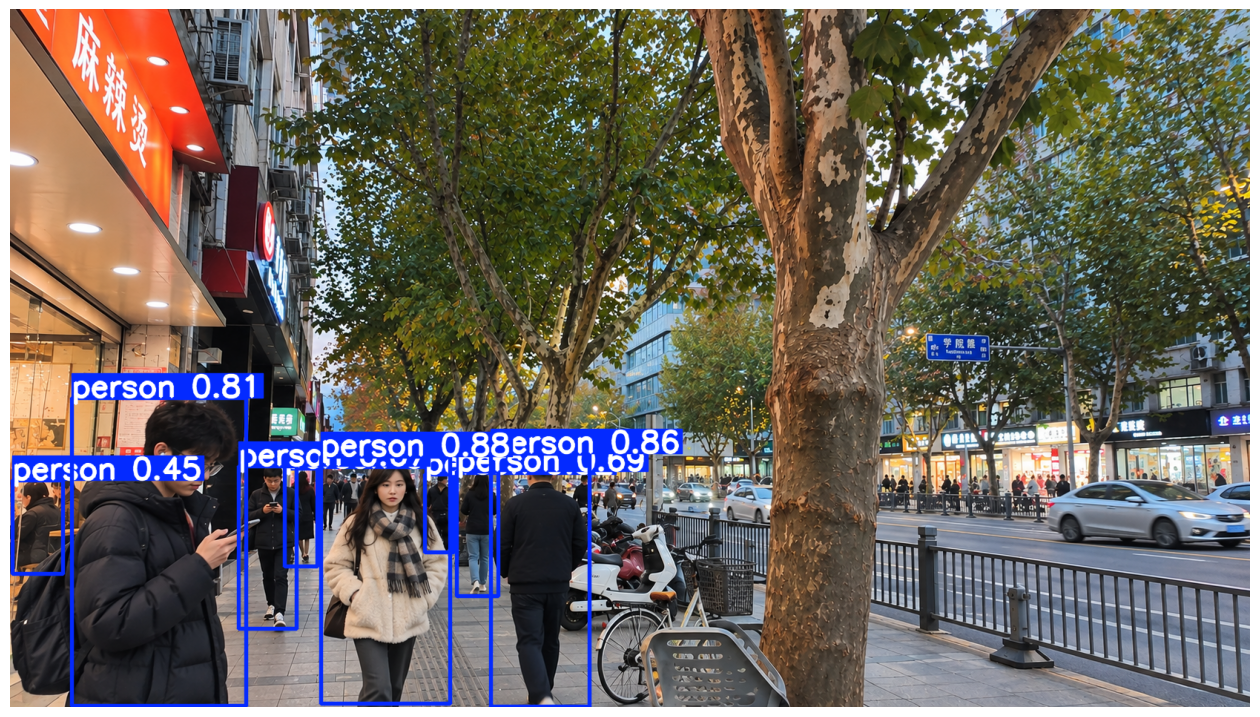

True

In [7]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# 加载 YOLO 模型
model = YOLO("yolo11n.pt")

# 图片路径（改成你自己的）
image_path = "/Users/fengqiukai/学院路黄昏街景.png"

# 检测人物
# classes=[0] 表示只检测 person（人）
results = model.predict(
    source=image_path,
    conf=0.25,
    classes=[0]
)

# 获取检测结果
result = results[0]

# 统计人数
print(f"检测到 {len(result.boxes)} 个人")

# 绘制检测框
annotated_image = result.plot()

# 转换颜色并显示
plt.figure(figsize=(16, 10))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# 保存检测结果
cv2.imwrite("detected_people.jpg", annotated_image)


image 1/1 /Users/fengqiukai/温馨客厅里的缤纷动物与果物盛宴.png: 736x1280 (no detections), 684.6ms
Speed: 29.5ms preprocess, 684.6ms inference, 10.9ms postprocess per image at shape (1, 3, 736, 1280)
检测到 0 个人


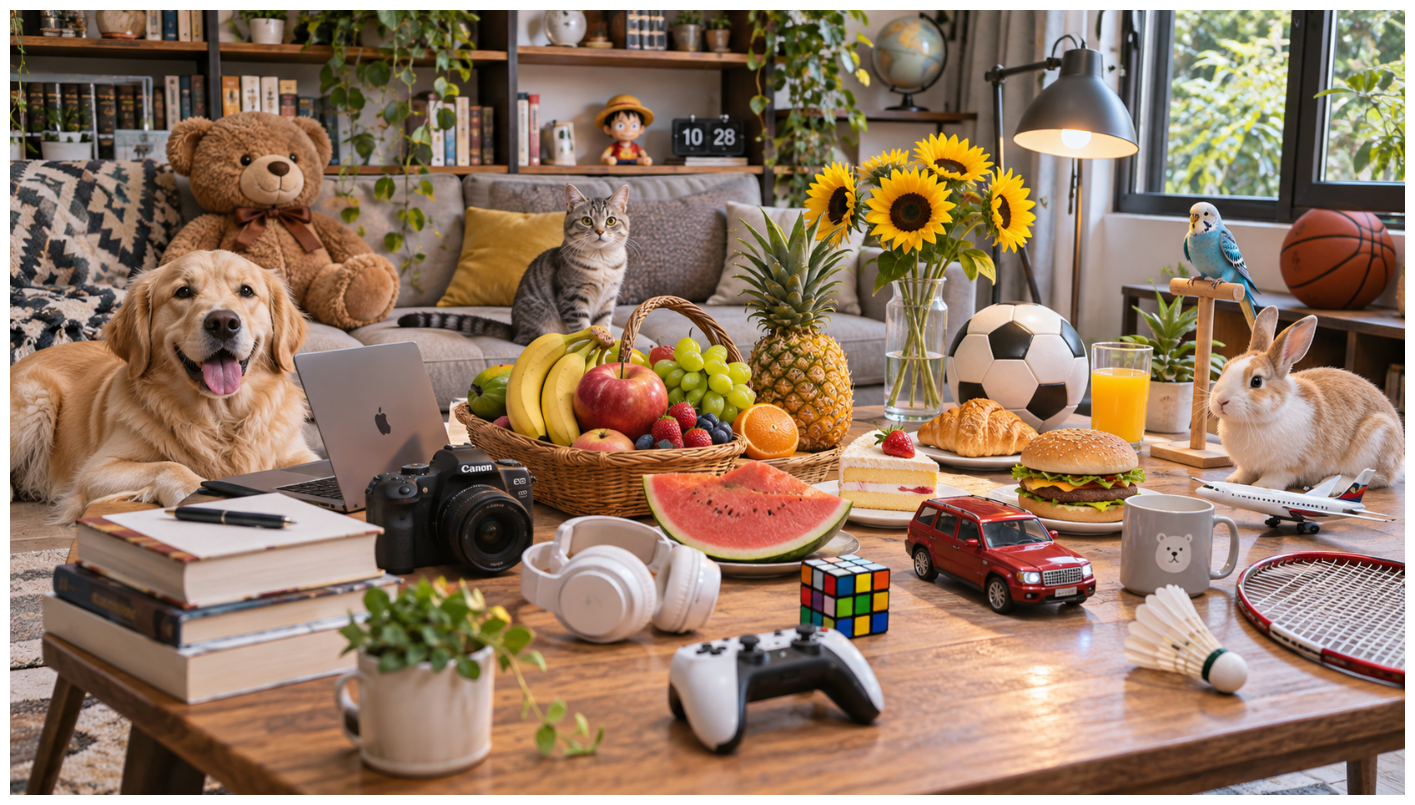

True

In [10]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# 1. 加载本地 PT 模型（修改为你的实际路径）
model = YOLO("/Users/fengqiukai/Downloads/yolo26l.pt")

# 2. 图片路径
image_path = "/Users/fengqiukai/温馨客厅里的缤纷动物与果物盛宴.png"

# 3. 开始识别
results = model.predict(
    source=image_path,
    conf=0.15,       # 降低置信度，尽量识别远处的人
    iou=0.5,        # NMS 重叠阈值
    imgsz=1280,     # 提高输入分辨率
    classes=[0],    # 只检测人物（适用于 COCO 类别编号）
    device="cpu"    # Mac 可尝试改为 "mps"
)

# 4. 获取检测结果
result = results[0]

# 5. 统计人数
print(f"检测到 {len(result.boxes)} 个人")

# 6. 绘制识别框
annotated = result.plot()

plt.figure(figsize=(18, 12))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# 7. 保存图片
cv2.imwrite("people_detected.jpg", annotated)


image 1/1 /Users/fengqiukai/温馨客厅里的缤纷动物与果物盛宴.png: 736x1280 1 car, 1 airplane, 1 truck, 1 bird, 3 cats, 1 dog, 2 sports balls, 4 cups, 1 bowl, 2 bananas, 3 apples, 1 sandwich, 1 orange, 1 cake, 4 couchs, 12 potted plants, 6 dining tables, 1 laptop, 1 remote, 27 books, 1 clock, 3 vases, 1 teddy bear, 681.5ms
Speed: 4.8ms preprocess, 681.5ms inference, 9.7ms postprocess per image at shape (1, 3, 736, 1280)
检测到 79 个物体
cup: 96.73%
sandwich: 96.53%
book: 94.29%
dog: 93.04%
cup: 92.04%
vase: 90.70%
book: 90.31%
cat: 89.22%
cake: 89.03%
laptop: 87.37%
apple: 87.13%
book: 87.03%
teddy bear: 85.84%
sports ball: 84.95%
orange: 80.94%
bird: 78.80%
potted plant: 74.15%
apple: 71.23%
sports ball: 70.77%
couch: 68.52%
potted plant: 67.18%
banana: 65.30%
cup: 63.67%
potted plant: 62.92%
potted plant: 60.23%
cup: 60.08%
car: 57.81%
book: 57.18%
book: 53.05%
book: 52.87%
book: 51.91%
potted plant: 51.26%
remote: 50.52%
book: 50.39%
book: 49.89%
clock: 49.53%
book: 49.52%
cat: 48.51%
book: 47.83%
book: 4

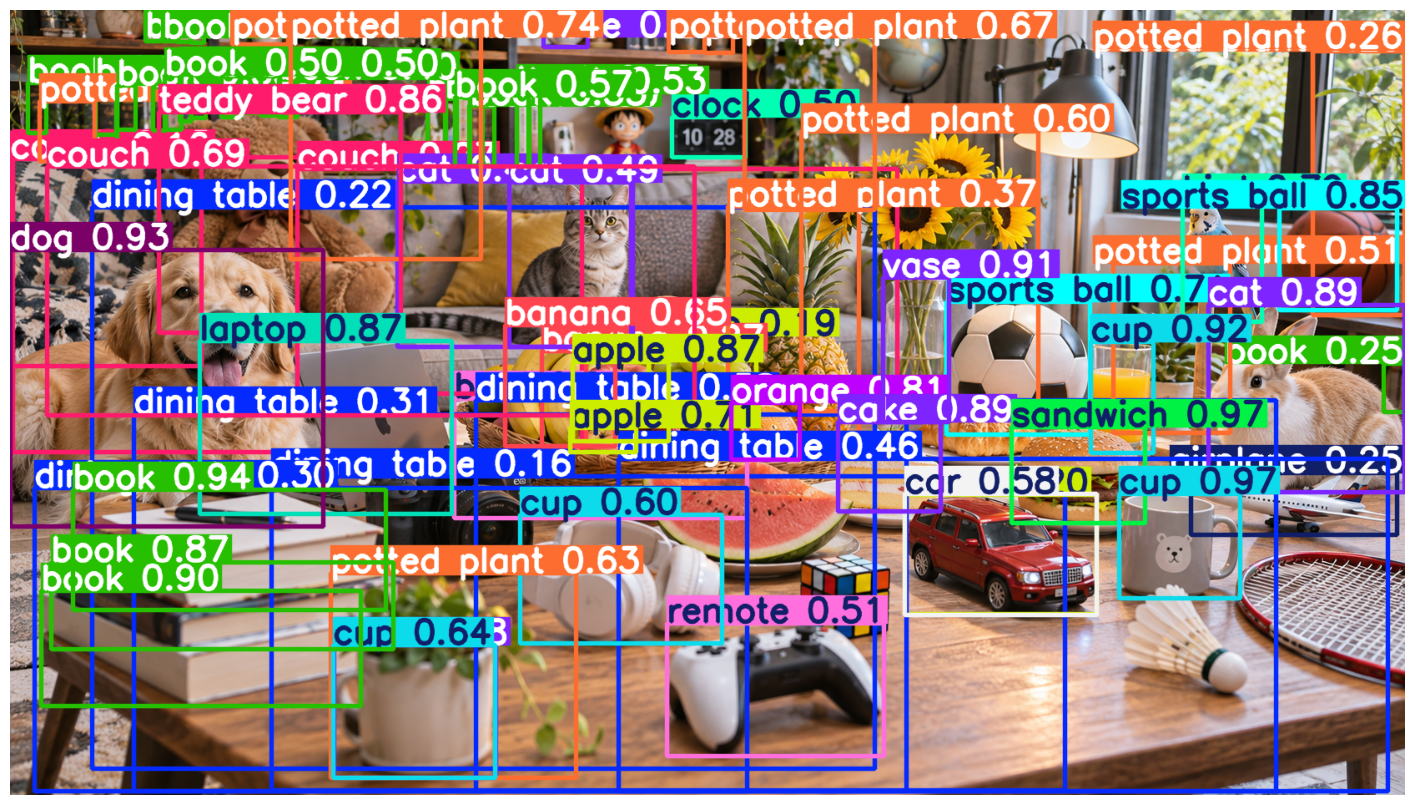

True

In [11]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# 加载目标检测模型
model = YOLO("/Users/fengqiukai/Downloads/yolo26l.pt")

# 图片路径
image_path = "/Users/fengqiukai/温馨客厅里的缤纷动物与果物盛宴.png"

# 检测所有物体
results = model.predict(
    source=image_path,
    conf=0.15,
    imgsz=1280,
    device="cpu"
)

result = results[0]

# 输出检测数量
print(f"检测到 {len(result.boxes)} 个物体")

# 输出每个物体的名称
for box in result.boxes:
    cls_id = int(box.cls[0])
    name = model.names[cls_id]
    confidence = float(box.conf[0])
    print(f"{name}: {confidence:.2%}")

# 显示检测结果
annotated = result.plot()

plt.figure(figsize=(18, 12))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# 保存结果
cv2.imwrite(
    "/Users/fengqiukai/Downloads/detected_objects.jpg",
    annotated
)